# 5 · Sensitivity to the calibration (leave-one-view-out)

With 6 views of the master and a single shot per solid, an error cannot be estimated with classical statistics. Instead, we measure how much the result changes when recalibrating without one view at a time (jackknife): the excluded view is excluded from both the camera and the light plane. The view at z = 350 mm is not excluded because it defines the reference.

The same computation on synthetic data tells how much of the sensitivity belongs to the algorithm and how much to the setup.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, FIGURES = ROOT / "data", ROOT / "docs" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from lightsheet3d.pipeline import calibrate_camera
from lightsheet3d.solids import CORPO5, CORPO6
from lightsheet3d.synthetic import Scene, write_dataset
from lightsheet3d.uncertainty import jackknife_se, leave_one_view_out

## Real data

In [2]:
camera = calibrate_camera(DATA / "camera_calibration")
print(f"centers discarded as wrong: {int((~camera.inliers).sum())} out of {len(camera.inliers)} "
      f"(per view: { {int(z): int((~camera.inliers[camera.view_ids == z]).sum()) for z in sorted(set(camera.view_ids))} })")

REAL = {
    "Corpo 6": leave_one_view_out(camera, DATA / "light_plane_calibration", DATA / "scans" / "30o34.jpg", CORPO6),
    "Corpo 5": leave_one_view_out(camera, DATA / "light_plane_calibration", DATA / "scans" / "30o3.jpg", CORPO5),
}
for name, runs in REAL.items():
    print(f"\n{name}")
    for r in runs:
        label = "full" if r.excluded is None else f"without z = {r.excluded}"
        print(f"  {label:15s} median distance {r.median:.2f} mm | heights {np.round(r.heights, 1).tolist()}")

centers discarded as wrong: 9 out of 1028 (per view: {300: 0, 310: 0, 320: 9, 330: 0, 340: 0, 350: 0})



Corpo 6
  full            median distance 0.55 mm | heights [44.4, 24.1, 44.6]
  without z = 300 median distance 1.43 mm | heights [39.9, 21.5, 40.1]
  without z = 310 median distance 0.66 mm | heights [44.1, 23.9, 44.3]
  without z = 320 median distance 0.49 mm | heights [45.0, 24.6, 45.2]
  without z = 330 median distance 0.75 mm | heights [43.8, 23.7, 43.9]
  without z = 340 median distance 0.73 mm | heights [48.2, 26.3, 48.5]

Corpo 5
  full            median distance 0.62 mm | heights [34.9, 29.7, 45.5]
  without z = 300 median distance 1.46 mm | heights [31.2, 26.5, 40.9]
  without z = 310 median distance 0.79 mm | heights [34.7, 29.5, 45.3]
  without z = 320 median distance 0.64 mm | heights [35.4, 30.2, 46.1]
  without z = 330 median distance 0.80 mm | heights [34.4, 29.2, 44.9]
  without z = 340 median distance 1.85 mm | heights [38.1, 32.4, 49.6]


## Synthetic data (same geometry, 0.5 px noise)

In [3]:
with tempfile.TemporaryDirectory() as tmp:
    root, scan = write_dataset(Scene(), CORPO6, tmp, noise_px=0.5)
    cam = calibrate_camera(root / "camera_calibration")
    SYN = {"Synthetic, Corpo 6": leave_one_view_out(cam, root / "light_plane_calibration", root / "scans" / scan, CORPO6)}
for r in SYN["Synthetic, Corpo 6"]:
    label = "full" if r.excluded is None else f"without z = {r.excluded}"
    print(f"  {label:15s} median distance {r.median:.2f} mm | heights {np.round(r.heights, 1).tolist()}")

  full            median distance 0.16 mm | heights [45.3, 24.3, 45.4]
  without z = 310 median distance 0.17 mm | heights [45.2, 24.3, 45.4]
  without z = 320 median distance 0.17 mm | heights [45.2, 24.3, 45.4]
  without z = 330 median distance 0.16 mm | heights [45.3, 24.3, 45.4]
  without z = 340 median distance 0.17 mm | heights [45.2, 24.3, 45.4]


## Comparison

Corpo 6              maximum change in heights 4.5 mm | jackknife standard error of the median distance 0.64 mm
Corpo 5              maximum change in heights 4.6 mm | jackknife standard error of the median distance 0.94 mm
Synthetic, Corpo 6   maximum change in heights 0.0 mm | jackknife standard error of the median distance 0.01 mm


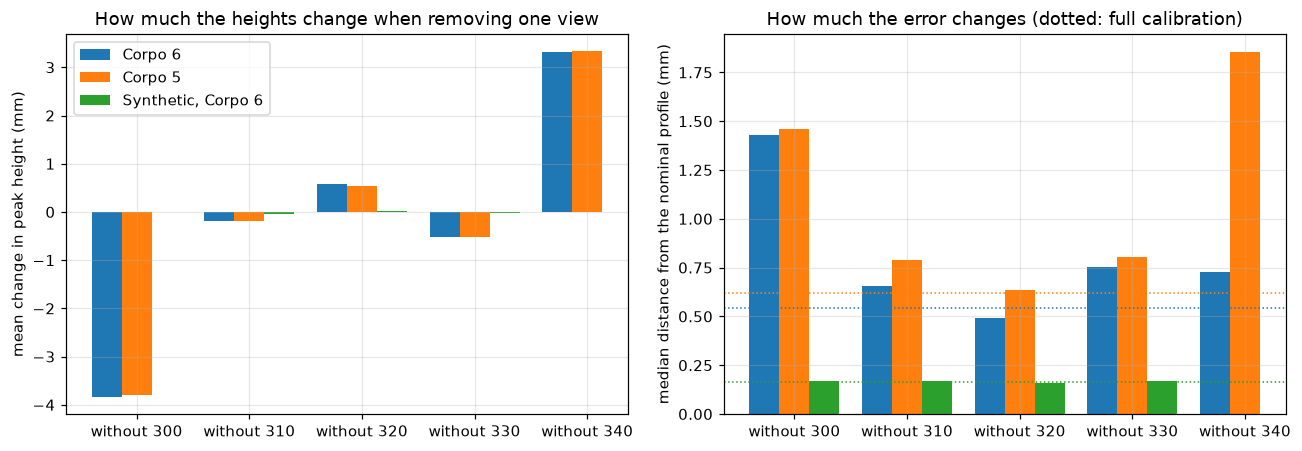

In [4]:
ALL = {**REAL, **SYN}
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2))
width = 0.8 / len(ALL)
for i, (name, runs) in enumerate(ALL.items()):
    full, loo = runs[0], runs[1:]
    x = np.arange(len(loo)) + i * width
    a.bar(x, [np.nanmean(r.heights - full.heights) for r in loo], width, label=name)
    b.bar(x, [r.median for r in loo], width, label=name)
    b.axhline(full.median, color=f"C{i}", ls=":", lw=1)
labels = [f"without {r.excluded}" for r in next(iter(ALL.values()))[1:]]
for ax in (a, b):
    ax.set_xticks(np.arange(len(labels)) + width * (len(ALL) - 1) / 2, labels)
a.set(ylabel="mean change in peak height (mm)", title="How much the heights change when removing one view")
b.set(ylabel="median distance from the nominal profile (mm)", title="How much the error changes (dotted: full calibration)")
a.legend(); fig.tight_layout(); fig.savefig(FIGURES / "uncertainty_leave_one_view_out.png", bbox_inches="tight")

for name, runs in ALL.items():
    loo = runs[1:]
    spread = max(float(np.nanmax(np.abs(r.heights - runs[0].heights))) for r in loo)
    print(f"{name:20s} maximum change in heights {spread:.1f} mm | jackknife standard error of the median distance {jackknife_se([r.median for r in loo]):.2f} mm")

## What it shows

* **Synthetic**: removing one view shifts the heights by about 0.1 mm. With consistent data, the algorithm does not depend on a single view.
* **Real**: removing the view at z = 300 mm lowers the heights by about 4.5 mm, removing the one at 340 mm raises them by about 4 mm, and in both cases the error on the profile doubles or worse. With all the views the result is close to the drawing, but it is a balance between views that are not consistent with each other, not a robust measurement.
* **A fix that came out of this**: without one view the camera improved a lot (rms from 7.3 to 3.9 px when removing 320): it contained 9 wrong centers, all in the last column of the master near the image edge, with residuals of about 67 px. `calibrate_camera` now discards them (rms 3.6 px).